<a href="https://colab.research.google.com/github/Nancy727/Uncertainty-Aware-Multimodal-Deep-Learning-for-Autonomous-Driving-Risk-Prediction/blob/main/ProjectDL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip -q install -U gdown

In [ ]:
import gdown
import os

file_id = "15BbCvkT-n0OBIMHODH__IzEqyIKv65LX"
output_path = "/content/v1.0-mini.tgz"

url = f"https://drive.google.com/uc?id={file_id}"

success = gdown.download(
    url=url,
    output=output_path,
    quiet=False
)

if success and os.path.exists(output_path):
    print("Download completed!")
    print("File size:", round(os.path.getsize(output_path) / (1024**3), 2), "GiB")
else:
    print("Download failed. Check the sharing permissions.")

Downloading...
From (original): https://drive.google.com/uc?id=15BbCvkT-n0OBIMHODH__IzEqyIKv65LX
From (redirected): https://drive.google.com/uc?id=15BbCvkT-n0OBIMHODH__IzEqyIKv65LX&confirm=t&uuid=7939636e-6043-47c3-a27c-a0d619364075
To: /content/v1.0-mini.tgz
100%|██████████| 4.17G/4.17G [01:29<00:00, 46.5MB/s]

Download completed!
File size: 3.88 GiB


In [ ]:
import os
import tarfile

archive_path = "/content/v1.0-mini.tgz"

print("File exists:", os.path.exists(archive_path))
print("Valid tar archive:", tarfile.is_tarfile(archive_path))

!df -h /content

File exists: True
Valid tar archive: True
Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   47G   67G  42% /


In [ ]:
import os
import tarfile

archive_path = "/content/v1.0-mini.tgz"
extract_dir = "/content/nuimages"

os.makedirs(extract_dir, exist_ok=True)

with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(path=extract_dir, filter="data")

print("Extraction completed!")
print("Extracted items:", os.listdir(extract_dir)[:15])

Extraction completed!
Extracted items: ['samples', '.v1.0-mini.txt', 'LICENSE', 'maps', 'sweeps', 'v1.0-mini']


In [ ]:
import os

for root, dirs, files in os.walk("/content/nuimages"):
    print("Folder:", root)
    print("Files:", files[:5])
    if root.count(os.sep) >= 4:
        dirs[:] = []

Folder: /content/nuimages
Files: ['.v1.0-mini.txt', 'LICENSE']
Folder: /content/nuimages/samples
Files: []
Folder: /content/nuimages/samples/CAM_FRONT_LEFT
Files: ['n008-2018-08-30-15-16-55-0400__CAM_FRONT_LEFT__1535657119604799.jpg', 'n015-2018-10-08-15-36-50+0800__CAM_FRONT_LEFT__1538984249904844.jpg', 'n015-2018-07-24-11-22-45+0800__CAM_FRONT_LEFT__1532402939104844.jpg', 'n015-2018-11-21-19-38-26+0800__CAM_FRONT_LEFT__1542800853404844.jpg', 'n015-2018-07-24-11-22-45+0800__CAM_FRONT_LEFT__1532402928104844.jpg']
Folder: /content/nuimages/samples/RADAR_FRONT_RIGHT
Files: ['n008-2018-08-01-15-16-36-0400__RADAR_FRONT_RIGHT__1533151605543536.pcd', 'n015-2018-10-08-15-36-50+0800__RADAR_FRONT_RIGHT__1538984244965129.pcd', 'n015-2018-11-21-19-38-26+0800__RADAR_FRONT_RIGHT__1542800989451591.pcd', 'n015-2018-11-21-19-38-26+0800__RADAR_FRONT_RIGHT__1542800373960828.pcd', 'n015-2018-11-21-19-38-26+0800__RADAR_FRONT_RIGHT__1542801006937440.pcd']
Folder: /content/nuimages/samples/RADAR_BACK_LEFT
F

In [ ]:
# 1. Imports and settings
import json, os, random
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

ROOT = Path("/content/nuimages")
META = ROOT / "v1.0-mini"
OUT = Path("/content/risk_results")
OUT.mkdir(exist_ok=True)

BATCH_SIZE = 8
EPOCHS = 5  # Increase after confirming the notebook runs
IMAGE_SIZE = 224
CLASS_NAMES = ["High", "Low", "Medium"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
FEATURES = [
    "max_pedestrian_height", "max_vehicle_height", "max_bicycle_height",
    "mean_pedestrian_height", "mean_vehicle_height"
]

for filename in ["sample_data.json", "sample_annotation.json", "instance.json",
                 "category.json", "calibrated_sensor.json", "sensor.json", "sample.json"]:
    if not (META / filename).exists():
        raise FileNotFoundError(f"Cannot find {META / filename}. Check ROOT/META paths.")


Device: cuda


In [ ]:
# 2. Read metadata and build lookups
def read_json(name):
    with open(META / name, encoding="utf-8") as f:
        return json.load(f)

sample_data = read_json("sample_data.json")
annotations = read_json("sample_annotation.json")
instances = read_json("instance.json")
categories = read_json("category.json")
calibrated = read_json("calibrated_sensor.json")
sensors = read_json("sensor.json")
samples = read_json("sample.json")

category_by_token = {x["token"]: x["name"] for x in categories}
instance_category = {
    x["token"]: category_by_token.get(x.get("category_token"), "unknown")
    for x in instances
}
calibrated_by_token = {x["token"]: x for x in calibrated}
sensor_by_token = {x["token"]: x for x in sensors}
sample_scene = {x["token"]: x.get("scene_token", "unknown") for x in samples}

annotations_by_sample = defaultdict(list)
for ann in annotations:
    annotations_by_sample[ann["sample_token"]].append(ann)

def object_type(category):
    c = category.lower()
    if "pedestrian" in c: return "pedestrian"
    if any(word in c for word in ["vehicle", "car", "truck", "bus", "trailer", "construction"]):
        return "vehicle"
    if "bicycle" in c or "motorcycle" in c: return "bicycle"
    return "other"

print("Samples:", len(samples), "| annotations:", len(annotations), "| camera records:", len(sample_data))


Samples: 404 | annotations: 18538 | camera records: 31206


In [ ]:
# 3. Build dataset using KEYFRAME camera images only
# Object counts create labels, so they are deliberately not used as model input features.
rows = []
missing_images = 0

for sd in sample_data:
    if not sd.get("is_key_frame", False):
        continue
    if not sd.get("filename", "").lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    cs = calibrated_by_token.get(sd.get("calibrated_sensor_token"), {})
    sensor = sensor_by_token.get(cs.get("sensor_token"), {})
    camera = sensor.get("channel", "")
    if not camera.startswith("CAM_"):
        continue

    image_path = ROOT / sd["filename"]
    if not image_path.exists():
        missing_images += 1
        continue

    counts = Counter()
    heights = defaultdict(list)
    for ann in annotations_by_sample.get(sd["sample_token"], []):
        typ = object_type(instance_category.get(ann.get("instance_token"), "unknown"))
        if typ == "other": continue
        counts[typ] += 1
        size = ann.get("size", [])
        if len(size) >= 3:
            heights[typ].append(float(size[2]))

    # Simple, explicit proxy label rule. Not an official dataset label.
    score = int(counts["pedestrian"] > 0) + int(counts["pedestrian"] >= 3) + int(counts["vehicle"] >= 3) + int(counts["bicycle"] > 0)
    label = "Low" if score <= 1 else "Medium" if score <= 2 else "High"

    def max_or_zero(x): return max(x) if x else 0.0
    def mean_or_zero(x): return float(np.mean(x)) if x else 0.0

    rows.append({
        "image_path": str(image_path),
        "scene": sample_scene.get(sd["sample_token"], "unknown"),
        "camera": camera,
        "label": label,
        "max_pedestrian_height": max_or_zero(heights["pedestrian"]),
        "max_vehicle_height": max_or_zero(heights["vehicle"]),
        "max_bicycle_height": max_or_zero(heights["bicycle"]),
        "mean_pedestrian_height": mean_or_zero(heights["pedestrian"]),
        "mean_vehicle_height": mean_or_zero(heights["vehicle"])
    })

df = pd.DataFrame(rows)
if df.empty:
    raise ValueError("No keyframe camera images found. Check the paths and metadata.")
df.to_csv(OUT / "dataset.csv", index=False)

print("Images used:", len(df), "| missing images:", missing_images)
print("\nCamera counts:\n", df["camera"].value_counts())
print("\nProxy-label counts:\n", df["label"].value_counts())
print("Saved:", OUT / "dataset.csv")


Images used: 2424 | missing images: 0

Camera counts:
 camera
CAM_FRONT          404
CAM_FRONT_RIGHT    404
CAM_BACK_RIGHT     404
CAM_BACK           404
CAM_BACK_LEFT      404
CAM_FRONT_LEFT     404
Name: count, dtype: int64

Proxy-label counts:
 label
High      1704
Low        480
Medium     240
Name: count, dtype: int64
Saved: /content/risk_results/dataset.csv


In [ ]:
# 4. Split by scene to reduce leakage between nearby frames
groups = df["scene"].astype(str).values
if len(set(groups)) < 3:
    raise ValueError("At least three scenes are needed for train/validation/test split.")

split1 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trainval_i, test_i = next(split1.split(df, groups=groups))
trainval = df.iloc[trainval_i].reset_index(drop=True)
test_df = df.iloc[test_i].reset_index(drop=True)

split2 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED + 1)
train_i, val_i = next(split2.split(trainval, groups=trainval["scene"].astype(str)))
train_df = trainval.iloc[train_i].reset_index(drop=True)
val_df = trainval.iloc[val_i].reset_index(drop=True)

assert set(train_df.scene).isdisjoint(set(val_df.scene))
assert set(train_df.scene).isdisjoint(set(test_df.scene))
assert set(val_df.scene).isdisjoint(set(test_df.scene))

# Fit scaler on training data only.
scaler = StandardScaler()
train_df.loc[:, FEATURES] = scaler.fit_transform(train_df[FEATURES])
val_df.loc[:, FEATURES] = scaler.transform(val_df[FEATURES])
test_df.loc[:, FEATURES] = scaler.transform(test_df[FEATURES])

pd.concat([
    train_df.assign(split="train"), val_df.assign(split="validation"),
    test_df.assign(split="test")
]).to_csv(OUT / "splits.csv", index=False)

print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")
print("Train labels:", train_df.label.value_counts().to_dict())
print("Validation labels:", val_df.label.value_counts().to_dict())
print("Test labels:", test_df.label.value_counts().to_dict())


Train: 1458 | Validation: 480 | Test: 486
Train labels: {'High': 942, 'Low': 348, 'Medium': 168}
Validation labels: {'High': 378, 'Medium': 60, 'Low': 42}
Test labels: {'High': 384, 'Low': 90, 'Medium': 12}


In [ ]:
# 5. Image dataset and loaders
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

class RiskDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row.image_path) as im:
            image = self.transform(im.convert("RGB"))
        features = torch.tensor(row[FEATURES].astype(float).values, dtype=torch.float32)
        label = torch.tensor(CLASS_TO_ID[row.label], dtype=torch.long)
        return image, features, label

train_loader = DataLoader(RiskDataset(train_df, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(RiskDataset(val_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(RiskDataset(test_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Loaders ready.")


Loaders ready.


In [ ]:
# 6. Five model backbones + numeric feature fusion
# Set PRETRAINED=False if Colab cannot download ImageNet weights.
PRETRAINED = True

def get_backbone(name):
    if name == "CustomCNN":
        class CNN(nn.Module):
            def __init__(self):
                super().__init__()
                self.net = nn.Sequential(
                    nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1)
                )
                self.out_features = 128
            def forward(self, x): return self.net(x).flatten(1)
        return CNN()

    if name == "ResNet50":
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if PRETRAINED else None)
        dim = m.fc.in_features; m.fc = nn.Identity()
    elif name == "EfficientNetB0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if PRETRAINED else None)
        dim = m.classifier[1].in_features; m.classifier = nn.Identity()
    elif name == "DenseNet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT if PRETRAINED else None)
        dim = m.classifier.in_features; m.classifier = nn.Identity()
    elif name == "MobileNetV3Large":
        m = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT if PRETRAINED else None)
        dim = m.classifier[0].in_features; m.classifier = nn.Identity()
    else:
        raise ValueError(name)
    m.out_features = dim
    return m

class RiskModel(nn.Module):
    def __init__(self, name):
        super().__init__()
        self.image_model = get_backbone(name)
        self.numeric_model = nn.Sequential(nn.Linear(len(FEATURES), 32), nn.ReLU())
        self.classifier = nn.Sequential(
            nn.Linear(self.image_model.out_features + 32, 128),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 3)
        )
    def forward(self, image, numeric):
        image_features = self.image_model(image)
        numeric_features = self.numeric_model(numeric)
        return self.classifier(torch.cat([image_features, numeric_features], dim=1))

MODEL_NAMES = ["CustomCNN", "ResNet50", "EfficientNetB0", "DenseNet121", "MobileNetV3Large"]


In [ ]:
# 7. Training and evaluation functions
train_ids = train_df.label.map(CLASS_TO_ID).values
present = np.unique(train_ids)
weights = compute_class_weight(class_weight="balanced", classes=present, y=train_ids)
class_weights = torch.ones(3)
for c, w in zip(present, weights): class_weights[c] = w
criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))

def evaluate(model, loader):
    model.eval()
    total_loss, ys, preds, probs_all = 0, [], [], []
    with torch.no_grad():
        for images, features, labels in loader:
            images, features, labels = images.to(DEVICE), features.to(DEVICE), labels.to(DEVICE)
            logits = model(images, features)
            total_loss += criterion(logits, labels).item() * len(labels)
            probs = torch.softmax(logits, 1)
            ys.extend(labels.cpu().numpy())
            preds.extend(logits.argmax(1).cpu().numpy())
            probs_all.extend(probs.cpu().numpy())
    return (total_loss / max(1, len(ys)), np.array(ys), np.array(preds), np.array(probs_all))

def train_one(name):
    model = RiskModel(name).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    best_loss, best_state = float("inf"), None
    for epoch in range(EPOCHS):
        model.train()
        for images, features, labels in train_loader:
            images, features, labels = images.to(DEVICE), features.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(images, features), labels)
            loss.backward()
            optimizer.step()
        val_loss, yv, pv, _ = evaluate(model, val_loader)
        val_f1 = f1_score(yv, pv, average="macro", zero_division=0)
        print(f"{name} | epoch {epoch+1}/{EPOCHS} | val loss={val_loss:.4f} | val macro-F1={val_f1:.4f}")
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if best_state is not None:
        model.load_state_dict(best_state)
    torch.save(model.state_dict(), OUT / f"{name}.pt")
    return model


In [ ]:
# 8. Train models and compare on the held-out test set
results = []
trained = {}
test_probs = {}

for name in MODEL_NAMES:
    print("\n" + "=" * 50 + "\nTraining", name)
    model = train_one(name)
    trained[name] = model
    _, y_true, y_pred, probs = evaluate(model, test_loader)
    test_probs[name] = probs
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    })
    print(classification_report(y_true, y_pred, labels=[0,1,2], target_names=CLASS_NAMES, zero_division=0))

results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False)
results_df.to_csv(OUT / "model_comparison.csv", index=False)
display(results_df)



Training CustomCNN
CustomCNN | epoch 1/5 | val loss=0.8727 | val macro-F1=0.5289
CustomCNN | epoch 2/5 | val loss=0.8096 | val macro-F1=0.5901
CustomCNN | epoch 3/5 | val loss=0.8306 | val macro-F1=0.5642
CustomCNN | epoch 4/5 | val loss=0.7610 | val macro-F1=0.5820
CustomCNN | epoch 5/5 | val loss=0.7430 | val macro-F1=0.5796
              precision    recall  f1-score   support

        High       0.96      0.82      0.89       384
         Low       1.00      1.00      1.00        90
      Medium       0.00      0.00      0.00        12

    accuracy                           0.84       486
   macro avg       0.65      0.61      0.63       486
weighted avg       0.95      0.84      0.89       486


Training ResNet50
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 178MB/s]


ResNet50 | epoch 1/5 | val loss=2.5521 | val macro-F1=0.2848
ResNet50 | epoch 2/5 | val loss=2.6127 | val macro-F1=0.2797
ResNet50 | epoch 3/5 | val loss=2.6320 | val macro-F1=0.2825
ResNet50 | epoch 4/5 | val loss=2.5094 | val macro-F1=0.2371
ResNet50 | epoch 5/5 | val loss=3.1420 | val macro-F1=0.2313
              precision    recall  f1-score   support

        High       0.79      0.95      0.86       384
         Low       0.19      0.06      0.09        90
      Medium       0.00      0.00      0.00        12

    accuracy                           0.76       486
   macro avg       0.33      0.33      0.32       486
weighted avg       0.66      0.76      0.70       486


Training EfficientNetB0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 149MB/s]


EfficientNetB0 | epoch 1/5 | val loss=1.2963 | val macro-F1=0.2616
EfficientNetB0 | epoch 2/5 | val loss=2.1395 | val macro-F1=0.2728
EfficientNetB0 | epoch 3/5 | val loss=1.9867 | val macro-F1=0.2813
EfficientNetB0 | epoch 4/5 | val loss=2.0979 | val macro-F1=0.3008
EfficientNetB0 | epoch 5/5 | val loss=1.9831 | val macro-F1=0.3392
              precision    recall  f1-score   support

        High       0.79      0.93      0.86       384
         Low       0.27      0.07      0.11        90
      Medium       0.08      0.08      0.08        12

    accuracy                           0.75       486
   macro avg       0.38      0.36      0.35       486
weighted avg       0.68      0.75      0.70       486


Training DenseNet121
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 124MB/s]


DenseNet121 | epoch 1/5 | val loss=2.0423 | val macro-F1=0.2880
DenseNet121 | epoch 2/5 | val loss=2.2197 | val macro-F1=0.2677
DenseNet121 | epoch 3/5 | val loss=2.2938 | val macro-F1=0.2877
DenseNet121 | epoch 4/5 | val loss=2.8203 | val macro-F1=0.2669
DenseNet121 | epoch 5/5 | val loss=2.6157 | val macro-F1=0.2494
              precision    recall  f1-score   support

        High       0.79      0.99      0.88       384
         Low       0.20      0.01      0.02        90
      Medium       0.00      0.00      0.00        12

    accuracy                           0.78       486
   macro avg       0.33      0.33      0.30       486
weighted avg       0.66      0.78      0.70       486


Training MobileNetV3Large
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 122MB/s] 


MobileNetV3Large | epoch 1/5 | val loss=1.1501 | val macro-F1=0.3520
MobileNetV3Large | epoch 2/5 | val loss=1.6962 | val macro-F1=0.2884
MobileNetV3Large | epoch 3/5 | val loss=2.5113 | val macro-F1=0.3108
MobileNetV3Large | epoch 4/5 | val loss=2.4243 | val macro-F1=0.3261
MobileNetV3Large | epoch 5/5 | val loss=2.8799 | val macro-F1=0.2947
              precision    recall  f1-score   support

        High       0.80      0.98      0.88       384
         Low       0.53      0.11      0.18        90
      Medium       0.00      0.00      0.00        12

    accuracy                           0.79       486
   macro avg       0.44      0.36      0.35       486
weighted avg       0.73      0.79      0.73       486



,model,accuracy,balanced_accuracy,macro_f1
0,CustomCNN,0.835391,0.607639,0.629213
4,MobileNetV3Large,0.792181,0.362558,0.354934
2,EfficientNetB0,0.753086,0.361632,0.349776
1,ResNet50,0.757202,0.333623,0.315465
3,DenseNet121,0.783951,0.333565,0.299888


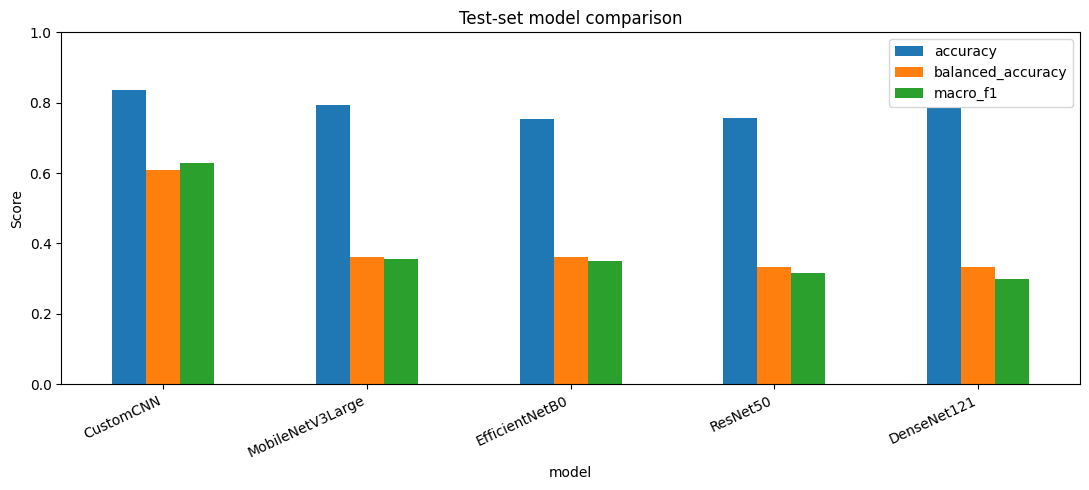

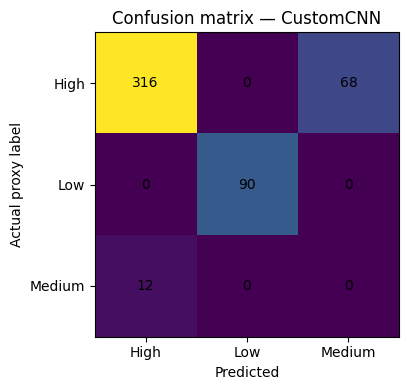

Best by macro-F1: CustomCNN


In [ ]:
# 9. Comparison graph and confusion matrix for the best macro-F1 model
ax = results_df.plot(x="model", y=["accuracy", "balanced_accuracy", "macro_f1"], kind="bar", figsize=(11, 5))
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("Test-set model comparison")
plt.xticks(rotation=25, ha="right"); plt.tight_layout()
plt.savefig(OUT / "model_comparison.png", dpi=180); plt.show()

best_name = results_df.iloc[0]["model"]
_, y_true, y_pred, _ = evaluate(trained[best_name], test_loader)
cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
plt.figure(figsize=(5,4))
plt.imshow(cm)
plt.xticks(range(3), CLASS_NAMES); plt.yticks(range(3), CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("Actual proxy label")
plt.title(f"Confusion matrix — {best_name}")
for i in range(3):
    for j in range(3): plt.text(j, i, cm[i,j], ha="center", va="center")
plt.tight_layout(); plt.savefig(OUT / "confusion_matrix.png", dpi=180); plt.show()
print("Best by macro-F1:", best_name)


In [ ]:
# 10. Monte Carlo dropout uncertainty for the best model
# Repeated stochastic forward passes estimate uncertainty from the dropout layer.
best_model = trained[best_name]
best_model.eval()
for module in best_model.modules():
    if isinstance(module, nn.Dropout): module.train()

all_y, pass_probs = [], []
with torch.no_grad():
    for images, features, labels in test_loader:
        images, features = images.to(DEVICE), features.to(DEVICE)
        batch_passes = []
        for _ in range(20):
            batch_passes.append(torch.softmax(best_model(images, features), dim=1).cpu().numpy())
        pass_probs.append(np.stack(batch_passes, axis=0))
        all_y.extend(labels.numpy())

# Concatenate along the example dimension: [passes, examples, classes]
probs = np.concatenate(pass_probs, axis=1)
mean_probs = probs.mean(axis=0)
variance = probs.var(axis=0).mean(axis=1)
pred = mean_probs.argmax(axis=1)
uncertainty = pd.DataFrame({
    "true_label": [CLASS_NAMES[i] for i in all_y],
    "predicted_label": [CLASS_NAMES[i] for i in pred],
    "correct": pred == np.array(all_y),
    "mean_probability_variance": variance
})
uncertainty.to_csv(OUT / "uncertainty.csv", index=False)
print("Mean probability variance:", float(variance.mean()))
print("Saved results to:", OUT)


Mean probability variance: 0.0026401537470519543
Saved results to: /content/risk_results
